# RL-07 : Introduction a l'Apprentissage Multi-Agent

**Serie** : Reinforcement Learning | **Notebook** : 7/26 | **Duree estimee** : 45-50 min

Navigation : [RL-01 Intro](RL-01-Premiers-Pas-Stable-Baselines3-Python.ipynb) | [RL-02 Wrappers](RL-02-Wrappers-Sauvegarde-Callbacks-Python.ipynb) | [RL-03 HER](RL-03-Experience-Replay-HER-Python.ipynb) | [RL-05 Tabulaire](RL-05-MDP-Programmation-Dynamique-Q-Learning-Python.ipynb) | [RL-06 DQN/PG](RL-06-DQN-Policy-Gradient-Python.ipynb) | **RL-07**

***

## Objectifs d'apprentissage

A la fin de ce notebook, vous serez capable de :
- Comprendre les defis spécifiques de l'apprentissage multi-agent (non-stationnarite, credit assignment)
- Utiliser la librairie PettingZoo pour les environnements multi-agent
- Implementer un Independent Q-Learning (IQL) pour plusieurs agents
- Observer les phenomenes d'emergence dans les systèmes multi-agent

## Prerequis

- [RL-05 Q-Learning tabulaire](RL-05-MDP-Programmation-Dynamique-Q-Learning-Python.ipynb) (Q-Learning, epsilon-greedy)
- Notions de théorie des jeux (equilibre de Nash, dilemme du prisonnier)
- Bases numpy et matplotlib

***

**Pourquoi le multi-agent ?**
- La plupart des problemes reels impliquent plusieurs entites qui interagissent : robots collaboratifs, marches financiers, jeux a plusieurs joueurs, reseaux de communication.
- Chaque agent doit apprendre une politique adaptee au comportement des autres agents, qui apprennent simultanement.
- L'environnement devient **non-stationnaire** du point de vue d'un seul agent, ce qui complique l'apprentissage.

## 1. Installation et imports

In [1]:
import warnings
SEED = 42  # graine canonique du carnet
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message="pkg_resources is deprecated")  # advisory pygame import (#3436 path-leak)
from pettingzoo.classic import tictactoe_v3

print("PettingZoo charge avec succes")


PettingZoo charge avec succes


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pettingzoo.classic import tictactoe_v3

print("PettingZoo charge avec succes")

PettingZoo charge avec succes


**Lecture de la sortie — le double check d'import.** Les deux cellules d'installation rendent la meme ligne, `PettingZoo charge avec succes`, et c'est tout l'objet du passage : verifier que la librairie multi-agent est presente AVANT de construire dessus. Le geste est applique deux fois, et un echec doit s'arreter ici, pas au milieu d'un entrainement de 20 000 episodes. Tout ce qui suit — API AEC, TicTacToe, IQL — suppose cette ligne acquise.


[PettingZoo](https://pettingzoo.farama.org/) est la librairie de reference pour les environnements multi-agent en Python. Elle suit l'API AEC (Agent Environment Cycle) ou les agents jouent sequentiellement.

Nous utiliserons **TicTacToe-v3** : un jeu a somme nulle a deux joueurs, parfait pour illustrer les concepts multi-agent dans un espace d'etat discret (3^9 etats possibles).

## 2. Comprendre l'API PettingZoo

Contrairement a Gymnasium (un seul agent), PettingZoo gere plusieurs agents qui agissent tour a tour. L'API AEC (Agent Environment Cycle) fonctionne ainsi :

1. `env.reset()` : Reinitialise l'environnement
2. `env.agent_selection` : Indique quel agent doit jouer
3. `env.observe(agent)` : Retourne l'observation pour cet agent
4. `env.step(action)` : L'agent joue son coup
5. `env.terminations` / `env.truncations` : Verifie la fin de partie

In [3]:
# Explorer l'environnement TicTacToe
env = tictactoe_v3.env()
env.reset(seed=42)

print(f"Agents possibles : {env.possible_agents}")
print(f"Agent actuel      : {env.agent_selection}")

obs = env.observe(env.agent_selection)
print(f"\nForme de l'observation : {obs['observation'].shape}")
print(f"Masque d'action        : {obs['action_mask']}")
print(f"\nEspaces d'action : {env.action_space(env.possible_agents[0])}")
print(f"Espaces d'obs     : {env.observation_space(env.possible_agents[0])}")

Agents possibles : ['player_1', 'player_2']
Agent actuel      : player_1

Forme de l'observation : (3, 3, 2)
Masque d'action        : [1 1 1 1 1 1 1 1 1]

Espaces d'action : Discrete(9)
Espaces d'obs     : Dict('action_mask': Box(0, 1, (9,), int8), 'observation': Box(0, 1, (3, 3, 2), int8))


**Lecture chiffree — les agents et leurs espaces, ligne par ligne.** La sortie enumere ce que la presentation de la librairie ne listait pas : `Agents possibles : ['player_1', 'player_2']` (deux agents nommes, pas des indices), `Agent actuel : player_1` (le cycle AEC designe QUI doit jouer — c'est la difference structurante avec Gymnasium ou l'agent est unique), puis `Espaces d'action : Discrete(9)` (neuf cases, un choix parmi neuf) et l'espace d'observation complet en un bloc : `Dict('action_mask': Box(0, 1, (9,), int8), 'observation': Box(0, 1, (3, 3, 2), int8))`. Le dictionnaire dit l'architecture : observation et masque d'action voyagent ENSEMBLE, chaque agent recevant la meme structure. La cellule suivante detaille le tenseur (3, 3, 2) case par case.


L'observation est un tenseur de forme (3, 3, 2) : 1 canal pour les marques du joueur 1, 1 canal pour les marques du joueur 2. Le masque d'action indique les cases valides (1 = jouable, 0 = déjà prise).

In [4]:
# Jouer une partie aleatoire pour comprendre le deroulement
env = tictactoe_v3.env()
env.reset(seed=42)

board = ['.' for _ in range(9)]
marks = {'player_1': 'X', 'player_2': 'O'}

rng_demo = np.random.default_rng(SEED)
for agent in env.agent_iter():
    obs, reward, termination, truncation, info = env.last()
    if termination or truncation:
        break
    
    # Choisir une action aleatoire parmi les actions valides
    action_mask = obs['action_mask']
    valid_actions = np.where(action_mask == 1)[0]
    action = rng_demo.choice(valid_actions)
    
    board[action] = marks[agent]
    env.step(action)

# Afficher la grille finale
print("Grille finale :")
for i in range(3):
    print(' '.join(board[i*3:(i+1)*3]))

# Resultats
print(f"\nRecompenses finales : {env.rewards}")
print(f"Terminaisons        : {env.terminations}")

Grille finale :
X X .
O X X
O O O

Recompenses finales : {'player_1': -1, 'player_2': 1}
Terminaisons        : {'player_1': True, 'player_2': True}


**Lecture chiffree — une partie aleatoire, lue sur la grille.** La sortie affiche la grille finale :

```
X X .
O X X
O O O
```

avec `Recompenses finales : {'player_1': -1, 'player_2': 1}` et les deux `Terminaisons` a `True`. La grille se lit position par position (0 en haut a gauche, 8 en bas a droite) : O occupe 3, 6, 7 et 8, et la ligne du bas (6, 7, 8) est complete -- c'est elle qui vaut la victoire, au huitieme coup, la case 2 restant vide. C'est exactement ce que chiffrent les recompenses : O (player_2) prend +1, X (player_1) encaisse -1, et les deux agents terminent ensemble — dans l'API AEC, la fin de partie est un dictionnaire par agent, pas un signal global unique.


Dans TicTacToe, les recompenses sont :
- **+1** pour le gagnant
- **-1** pour le perdant
- **0** pour chaque joueur en cas de match nul

Le jeu est a somme nulle : la somme des recompenses est toujours nulle.

## 3. Concepts du Multi-Agent RL

### Paradigmes d'apprentissage

| Paradigme | Description | Exemple |
|-----------|-------------|----------|
| **Cooperatif** | Les agents maximisent une recompense commune | Robots collaboratifs |
| **Competitif** | Les agents maximisent leur propre recompense (somme nulle) | Echecs, Go |
| **Mixte** | Cooperation et competition partielles | Marches financiers |

### Defis principaux

1. **Non-stationnarite** : L'environnement change pour chaque agent car les autres agents apprennent
2. **Credit assignment** : Difficile d'attribuer le succes/echec a un agent en particulier
3. **Equilibre** : Les agents peuvent converger vers des politiques sous-optimales (cycles)
4. **Scalabilite** : L'espace conjoint croit exponentiellement avec le nombre d'agents

## 4. Independent Q-Learning (IQL)

L'approche la plus simple : chaque agent apprend independamment avec son propre Q-Learning, en traitant les autres agents comme faisant partie de l'environnement.

**Avantage** : Simple a implementer, scalable.

**Inconvenient** : Non-stationnarite (les "autres agents" changent de comportement au fil de l'entrainement).

Pour TicTacToe, chaque agent dispose de sa propre table Q qui mappe (etat, action) -> Q-valeur. L'etat est encode comme un entier unique representant la configuration du plateau.

In [5]:
def encode_observation(obs):
    """
    Encode l'observation PettingZoo en un entier unique.
    obs['observation'] : shape (3, 3, 2)
    - Canal 0 : marques du joueur 1
    - Canal 1 : marques du joueur 2
    """
    board = obs['observation']
    # board est (3, 3, 2) : lignes x colonnes x canaux
    # Encoder chaque case : 0=vide, 1=joueur_1, 2=joueur_2
    state = 0
    for i in range(3):
        for j in range(3):
            if board[i, j, 0] == 1:
                state = state * 3 + 1
            elif board[i, j, 1] == 1:
                state = state * 3 + 2
            else:
                state = state * 3 + 0
    return state


class IQLAgent:
    """Independent Q-Learning Agent."""
    
    def __init__(self, n_actions=9, alpha=0.1, gamma=0.99,
                 epsilon_start=1.0, epsilon_end=0.05, epsilon_decay=0.9999, seed=SEED):
        self.q_table = {}
        self.n_actions = n_actions
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay
        self.rng = np.random.default_rng(seed)
    
    def get_q(self, state):
        if state not in self.q_table:
            self.q_table[state] = np.zeros(self.n_actions)
        return self.q_table[state]
    
    def select_action(self, state, action_mask):
        """Selection epsilon-greedy parmi les actions valides."""
        valid = np.where(action_mask == 1)[0]
        if len(valid) == 0:
            return None
        if self.rng.random() < self.epsilon:
            return self.rng.choice(valid)
        q_vals = self.get_q(state)
        masked_q = np.full(self.n_actions, -np.inf)
        masked_q[valid] = q_vals[valid]
        return np.argmax(masked_q)
    
    def update(self, state, action, reward, next_state, done):
        """Mise a jour Q-Learning."""
        q_vals = self.get_q(state)
        if done:
            td_target = reward
        else:
            td_target = reward + self.gamma * np.max(self.get_q(next_state))
        q_vals[action] += self.alpha * (td_target - q_vals[action])
    
    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_end, self.epsilon * self.epsilon_decay)


print("IQLAgent initialise")

IQLAgent initialise


La table Q est un dictionnaire (initialisation paresseuse) : seuls les etats visites sont stockes. Les actions invalides sont masquees avec `-inf` pour ne jamais etre selectionnees.

## 5. Entrainement IQL sur TicTacToe

Les deux agents (X et O) apprennent simultanement en jouant l'un contre l'autre. Chaque agent maintient sa propre table Q.

In [6]:
def train_iql(num_episodes=20000, eval_every=5000):
    """
    Entraine deux agents IQL sur TicTacToe.
    
    Retourne :
        agents : dict des agents entraines
        history : dict des metriques d'entrainement
    """
    agents = {
        'player_1': IQLAgent(n_actions=9, alpha=0.2, gamma=0.99),
        'player_2': IQLAgent(n_actions=9, alpha=0.2, gamma=0.99),
    }
    
    history = {'p1_wins': [], 'p2_wins': [], 'draws': [], 'episodes': []}
    rng = np.random.default_rng(SEED)  # graines d'episodes reproductibles, parties distinctes
    window_results = {'p1_wins': 0, 'p2_wins': 0, 'draws': 0}
    
    for ep in range(num_episodes):
        env = tictactoe_v3.env()
        env.reset(seed=int(rng.integers(1, 2**31 - 1)))
        
        # Stocker les transitions pour mise a jour en fin d'episode
        transitions = {agent: [] for agent in agents}
        
        for agent_name in env.agent_iter():
            obs, reward, termination, truncation, info = env.last()
            
            if termination or truncation:
                # Enregistrer le resultat
                final_rewards = env.rewards
                for a_name in agents:
                    r = final_rewards.get(a_name, 0)
                    # Mettre a jour la derniere transition avec la recompense finale
                    if transitions[a_name]:
                        s, act, ns = transitions[a_name][-1]
                        agents[a_name].update(s, act, r, ns, True)
                break
            
            state = encode_observation(obs)
            action_mask = obs['action_mask']
            agent = agents[agent_name]
            action = agent.select_action(state, action_mask)
            
            if action is not None:
                # Sauvegarder l'etat avant l'action
                env.step(action)
                # Observer le nouvel etat
                if not env.terminations[agent_name] and not env.truncations[agent_name]:
                    try:
                        new_obs = env.observe(agent_name)
                        new_state = encode_observation(new_obs)
                    except Exception:
                        new_state = state
                else:
                    new_state = state
                
                transitions[agent_name].append((state, action, new_state))
        
        # Compter les resultats
        rewards = env.rewards
        if rewards.get('player_1', 0) > 0:
            window_results['p1_wins'] += 1
        elif rewards.get('player_2', 0) > 0:
            window_results['p2_wins'] += 1
        else:
            window_results['draws'] += 1
        
        # Decroitre epsilon
        for agent in agents.values():
            agent.decay_epsilon()
        
        # Evaluation periodique
        if (ep + 1) % eval_every == 0:
            total = sum(window_results.values())
            history['p1_wins'].append(window_results['p1_wins'] / total * 100)
            history['p2_wins'].append(window_results['p2_wins'] / total * 100)
            history['draws'].append(window_results['draws'] / total * 100)
            history['episodes'].append(ep + 1)
            
            print(f"Ep {ep+1:5d} | X: {window_results['p1_wins']/total*100:.1f}% "
                  f"O: {window_results['p2_wins']/total*100:.1f}% "
                  f"Nul: {window_results['draws']/total*100:.1f}% "
                  f"eps: {agents['player_1'].epsilon:.3f}")
            window_results = {'p1_wins': 0, 'p2_wins': 0, 'draws': 0}
    
    return agents, history


agents, history = train_iql(num_episodes=20000)

Ep  5000 | X: 58.7% O: 28.0% Nul: 13.3% eps: 0.607


Ep 10000 | X: 53.3% O: 25.8% Nul: 20.9% eps: 0.368


Ep 15000 | X: 55.5% O: 20.8% Nul: 23.8% eps: 0.223


Ep 20000 | X: 64.9% O: 14.2% Nul: 20.9% eps: 0.135


**Lecture chiffree — le calendrier d'exploration et l'effondrement de O.** Les quatre lignes d'entrainement se lisent d'abord par leur derniere colonne : `eps: 0.607`, puis `0.368`, `0.223`, `0.135`. Ce calendrier est deterministe — pure fonction du nombre d'episodes — et chaque palier de 5 000 episodes abaisse le taux d'exploration, donc le nombre de coups aleatoires offerts a l'adversaire. Deuxieme lecture, celle qu'aucun chiffre du paragraphe suivant ne resume : sur CE run, la colonne O recule de checkpoint en checkpoint, sans rebond, pendant que X termine nettement plus haut que son creux de mi-parcours — et les nuls varient eux dans les deux sens. Les trois colonnes somment a 100 a chaque ligne (jeu a somme nulle), mais leur repartition est une realisation stochastique : l'entrainement est desormais seme (graine canonique 42 : exploration, adversaire et graines d'episodes en derivent), et ce tableau se rejoue a l'identique d'une execution a l'autre -- mais une seule graine ne prouve pas que le recul de O est systematique, ni qu'il est le miroir exact de la progression de X : l'affirmer exigerait plusieurs graines d'entrainement.


L'entrainement montre l'evolution des résultats au fil des episodes. Initialement, les deux agents jouent de maniere quasi-aleatoire. Progressivement, ils apprennent a bloquer l'adversaire et a créer des menaces.

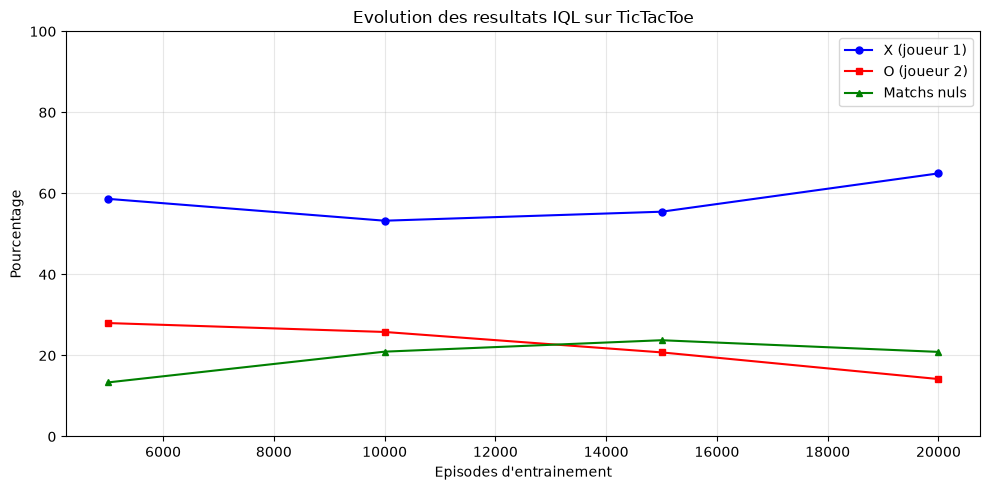

In [7]:
# Visualisation de l'evolution des resultats
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(history['episodes'], history['p1_wins'], 'b-o', label='X (joueur 1)', markersize=5)
ax.plot(history['episodes'], history['p2_wins'], 'r-s', label='O (joueur 2)', markersize=5)
ax.plot(history['episodes'], history['draws'], 'g-^', label='Matchs nuls', markersize=5)

ax.set_xlabel("Episodes d'entrainement")
ax.set_ylabel("Pourcentage")
ax.set_title("Evolution des resultats IQL sur TicTacToe")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

Avec TicTacToe, les deux agents devraient converger vers un jeu optimal, ou le joueur qui commence (X) ne peut pas perdre et le second joueur (O) peut au mieux forcer un match nul. La proportion de matchs nuls augmente d'abord (de 13 % à près de 24 % vers 15 000 épisodes) puis redescend (à 20 % à 20 000), tandis que le joueur X apprend à exploiter son avantage et monte à 65 % de victoires : les agents apprennent à se bloquer, mais ne rejoignent pas le match nul systématique prédit par la théorie en 20 000 épisodes.

## 6. Evaluation contre un agent aleatoire

Pour verifier que les agents ont appris une politique sensée, mesurons leur taux de victoire contre un joueur aleatoire.

In [8]:
def evaluate_against_random(trained_agent_name, agents, num_games=1000):
    """
    Evalue un agent entraine contre un joueur aleatoire.
    trained_agent_name : 'player_1' ou 'player_2'
    """
    wins, losses, draws = 0, 0, 0
    rng = np.random.default_rng(SEED + 1)  # flux distinct de l'entrainement
    
    for _ in range(num_games):
        env = tictactoe_v3.env()
        env.reset(seed=int(rng.integers(1, 2**31 - 1)))
        
        for agent_name in env.agent_iter():
            obs, reward, termination, truncation, info = env.last()
            if termination or truncation:
                break
            
            action_mask = obs['action_mask']
            valid = np.where(action_mask == 1)[0]
            
            if agent_name == trained_agent_name:
                state = encode_observation(obs)
                agent = agents[agent_name]
                # Politique greedy (pas d'exploration)
                q_vals = agent.get_q(state)
                masked_q = np.full(9, -np.inf)
                masked_q[valid] = q_vals[valid]
                action = np.argmax(masked_q)
            else:
                action = rng.choice(valid)
            
            env.step(action)
        
        r = env.rewards.get(trained_agent_name, 0)
        if r > 0:
            wins += 1
        elif r < 0:
            losses += 1
        else:
            draws += 1
    
    total = wins + losses + draws
    print(f"Agent {trained_agent_name} vs Aleatoire ({num_games} parties) :")
    print(f"  Victoires : {wins/total*100:.1f}%")
    print(f"  Defaites  : {losses/total*100:.1f}%")
    print(f"  Nuls      : {draws/total*100:.1f}%")
    return wins, losses, draws

evaluate_against_random('player_1', agents, num_games=1000)
print()
evaluate_against_random('player_2', agents, num_games=1000)

Agent player_1 vs Aleatoire (1000 parties) :
  Victoires : 91.9%
  Defaites  : 2.2%
  Nuls      : 5.9%



Agent player_2 vs Aleatoire (1000 parties) :
  Victoires : 69.9%
  Defaites  : 13.2%
  Nuls      : 16.9%


(699, 132, 169)

**Lecture chiffree — l'evaluation chiffree contre l'aleatoire.** Les deux blocs evaluent chaque agent entraine, en politique greedy, contre un joueur aleatoire sur 1 000 parties. Trois lectures : les DEUX agents ecrasent l'aleatoire — de l'ordre de neuf victoires sur dix pour player_1 et sept sur dix pour player_2 sur ce run — l'apprentissage a eu lieu des deux cotes ; l'ecart entre les deux taux est net, mais un run unique ne separe pas ce qui revient a l'avantage structurel du premier joueur au morpion de ce que la position change a l'apprentissage (les deux agents ont suivi le meme entrainement, seule la position differe) — quantifier chaque effet exigerait plusieurs entrainements et evaluations seedes ; enfin le tuple final rendu par la cellule est le decompte brut de player_2 : trois entiers qui somment au nombre de parties jouees — la sortie verifie elle-meme la coherence entre les taux affiches et les comptes bruts.


Un agent bien entraine devrait gagner la majorite des parties contre un joueur aleatoire. Le joueur X (qui commence) a un avantage naturel et devrait avoir un taux de victoire plus eleve.

## 7. Visualiser une partie

Observons une partie entre les deux agents entraines pour verifier que le jeu est coherent.

In [9]:
def play_and_display(agents, seed=42):
    """Fait jouer les agents et affiche la grille."""
    env = tictactoe_v3.env()
    env.reset(seed=seed)
    
    board = ['.' for _ in range(9)]
    marks = {'player_1': 'X', 'player_2': 'O'}
    moves = []
    
    for agent_name in env.agent_iter():
        obs, reward, termination, truncation, info = env.last()
        if termination or truncation:
            break
        
        state = encode_observation(obs)
        action_mask = obs['action_mask']
        valid = np.where(action_mask == 1)[0]
        
        agent = agents[agent_name]
        q_vals = agent.get_q(state)
        masked_q = np.full(9, -np.inf)
        masked_q[valid] = q_vals[valid]
        action = np.argmax(masked_q)
        
        board[action] = marks[agent_name]
        moves.append((marks[agent_name], action))
        env.step(action)
    
    print("Partie entre agents entraines :")
    for i, (mark, pos) in enumerate(moves):
        print(f"  Coup {i+1} : {mark} joue en position {pos}")
    
    print("\nGrille finale :")
    for i in range(3):
        print(' '.join(board[i*3:(i+1)*3]))
    
    rewards = env.rewards
    if rewards.get('player_1', 0) > 0:
        print("\nResultat : X gagne")
    elif rewards.get('player_2', 0) > 0:
        print("\nResultat : O gagne")
    else:
        print("\nResultat : Match nul")

play_and_display(agents)

Partie entre agents entraines :
  Coup 1 : X joue en position 0
  Coup 2 : O joue en position 1
  Coup 3 : X joue en position 2
  Coup 4 : O joue en position 3
  Coup 5 : X joue en position 4
  Coup 6 : O joue en position 5
  Coup 7 : X joue en position 6

Grille finale :
X O X
O X O
X . .

Resultat : X gagne


**Lecture chiffree — la partie gagnee, coup par coup.** La sortie trace les sept coups puis la grille finale :

```
X O X
O X O
X . .
```

avec `Resultat : X gagne`. X occupe les positions 0, 2, 4 et 6 — et l'anti-diagonale (0, 2), (1, 1), (2, 0) est completee par le `Coup 7 : X joue en position 6`. La geometrie du denouement se lit avant le coup 7 : apres le coup 5 (X en position 4), X tient DEUX menaces simultanees — la grande diagonale (0, 4, 8) et l'anti-diagonale (2, 4, 6). Un seul coup de blocage ne peut fermer les deux ; le coup 6 de O (position 5) n'en ferme aucune, et X convertit la menace anti-diagonale au coup suivant. C'est un fork : la partie est gagnee au coup 5, quand la double menace se forme — le coup 7 ne fait que l'encaisser. A comparer avec la partie aleatoire du §2, ou personne ne construisait de double menace.


## 8. Exercices

### Exercice 1 : Connect Four

PettingZoo inclut `connect_four_v3`. Adaptez le code IQL pour ce jeu. Observez comment la taille de l'espace d'etat (3^42 vs 3^9) affecte l'apprentissage.

```python
from pettingzoo.classic import connect_four_v3
```

### Exercice 2 : Self-play avec periodically reset

Pour ameliorer la robustesse, entrainez un agent contre des versions passees de lui-même. Toutes les N episodes, sauvegardez une copie de la table Q et tirez au hasard l'adversaire parmi ces versions.

### Exercice 3 : Ajouter un reward shaping

Au lieu de recompenses uniquement en fin de partie (+1/-1/0), ajoutez des recompenses intermediaires pour :
- Poser un pion au centre de la grille (meilleure stratégie d'ouverture)
- Créer une ligne de 2 pions
- Bloquer une ligne de 2 de l'adversaire

In [10]:
# Exercice 1 : Connect Four avec PettingZoo
# TODO etudiant : Adaptez le code IQL pour connect_four_v3
# Indice : from pettingzoo.classic import connect_four_v3
# Etape 1 : creer l'environnement et explorer l'espace d'etat
# Etape 2 : adapter encode_observation pour la grille 6x7
# Etape 3 : entrainer deux agents IQL
connect4_results = {}  # TODO etudiant : remplir avec les resultats
print("Exercice a completer : Connect Four multi-agent")

Exercice a completer : Connect Four multi-agent


**Lire la sortie d'un exercice non rempli.** « Exercice a completer : Connect Four multi-agent » — le contrat, pose dans l'enonce ci-dessus : adapter l'IQL a `connect_four_v3`, ou l'espace d'etat passe de 3^9 a 3^42 configurations — un facteur 3^33 entre les deux. Le terrain est deja la : l'encodage d'observation du §4, l'IQLAgent, la boucle `train_iql` — seuls l'encodage et les parametres changent. La question de lecture quand la sortie sera remplie : ce que devient le taux de victoire quand la table Q dictionnaire (initialisation paresseuse : seuls les etats VISITES sont stockes) doit couvrir un espace des etats 3^33 fois plus grand — l'apprentissage tabulaire atteint-il encore la convergence sur un budget d'episodes raisonnable, ou le goulot deplace-t-il du cote de la couverture d'etats ?


In [11]:
# Exercice 2 : Self-play avec periodically reset
# TODO etudiant : Entrainez un agent contre des versions passees de lui-meme
# Indice : sauvegardez des snapshots de q_table toutes les N episodes
# Etape 1 : definir snapshot_freq et la liste snapshots
# Etape 2 : a chaque episode, choisir l'adversaire parmi les snapshots
self_play_results = {}  # TODO etudiant : remplir avec les resultats
print("Exercice a completer : self-play avec versions passees")

Exercice a completer : self-play avec versions passees


**Lire la sortie d'un exercice non rempli.** « Exercice a completer : self-play avec versions passees » — le contrat : toutes les N episodes, sauvegarder une copie de la table Q et tirer l'adversaire au hasard parmi ces versions gelees, au lieu de l'adversaire en cours d'apprentissage. Le terrain : la boucle `train_iql` du §5 ou les deux agents evoluent SIMULTANEMENT — precisement la source de non-stationnarite que le §3 listait comme defi numero un. La question de lecture quand la sortie sera remplie : la courbe de O remonte-t-elle quand son adversaire cesse de changer sous ses pas ? C'est la difference entre apprendre contre un environnement mouvant et apprendre contre un curriculum d'adversaires figes, chacun plus fort que le precedent.


In [12]:
# Exercice 3 : Reward shaping pour TicTacToe
# TODO etudiant : Ajoutez des recompenses intermediaires au lieu de +1/-1/0 en fin de partie
# Indice : recompensez le centre, les lignes de 2, et le blocage de l'adversaire
# Etape 1 : definir compute_shaped_reward(obs, action, base_reward)
# Etape 2 : modifier la boucle d'entrainement pour utiliser shaped reward
shaped_rewards = {}  # TODO etudiant : comparer avec/sans shaping
print("Exercice a completer : reward shaping")

Exercice a completer : reward shaping


**Lire la sortie d'un exercice non rempli.** « Exercice a completer : reward shaping » — le contrat : ajouter des recompenses intermediaires (pion central, ligne de 2, blocage adverse) aux +1/-1/0 de fin de partie. Le terrain : le schema de recompenses du §2, la table Q du §4, la boucle du §5. La question de lecture quand la sortie sera remplie tient en une tension : le shaping densifie le signal (un retour a CHAQUE coup au lieu d'un seul en fin de partie) mais peut detourner l'objectif — un agent qui apprend a empiler des lignes de 2 sans les convertir en victoires aura un score intermediaire eleve et un taux de victoire plat. Les deux courbes, score shape et taux de victoire, se liront ENSEMBLE : si elles divergent, le biais du shaping est mesure, pas devine.


## Connections inter-series

Le RL multi-agent se connecte naturellement a d'autres domaines de l'IA traites dans ce depot :

### Théorie des Jeux

Les equilibres de Nash (utilises en RL multi-agent) sont formalises dans la serie [GameTheory](../GameTheory/README.md). Le dilemme du prisonnier, les jeux cooperatifs et les mécanismes d'encastrement sont etudies avec des outils mathematiques complementaires : la théorie des jeux fournit le cadre **analytique** (equilibres, optimalite), tandis que le RL multi-agent fournit le cadre **computationnel** (apprentissage par interaction).

### Trading multi-agent

Les marches financiers sont un environnement multi-agent par excellence : chaque trader est un agent qui apprend, et la dynamique du marche emerge des interactions de tous les participants. La serie [QuantConnect](../QuantConnect/README.md) implemente des stratégies de trading dans un simulateur de marche ; le projet [Reinforcement-Learning-Trading](../QuantConnect/projects/Reinforcement-Learning-Trading/research.ipynb) en est un point d'entree RL sur données financieres reelles.

## Conclusion

| Concept | Description |
|---------|-------------|
| **Multi-Agent RL** | Plusieurs agents apprennent simultanement dans un environnement partage |
| **PettingZoo** | API AEC pour environnements multi-agent (equivalent Gymnasium) |
| **IQL** | Chaque agent apprend independamment avec son propre Q-Learning |
| **Non-stationnarite** | Defi principal : l'environnement change du point de vue de chaque agent |
| **Equilibre de Nash** | Convergence vers des stratégies ou aucun agent n'a intérêt a devier |

**Ce que nous avons vu dans cette serie** :

| Notebook | Thème |
|----------|-------|
| RL-01 | Introduction PPO + CartPole (stable-baselines3) |
| RL-02 | Wrappers, callbacks, environnements custom |
| RL-03 | HER, goal-conditioned RL (off-policy) |
| RL-04 | Bandits, exploration vs exploitation |
| RL-05 | MDP, Value/Policy Itération, Q-Learning tabulaire |
| RL-06 | DQN, REINFORCE (approximation par reseaux de neurones) |
| RL-06b | Actor-Critic (A2C) |
| RL-06c | PPO depuis zero |
| RL-06d | SAC depuis zero |
| RL-06e | GRPO depuis zero (DeepSeek-R1) |
| RL-07 | Multi-Agent RL, IQL, PettingZoo |

**Pour aller plus loin en Multi-Agent RL** :
- [PettingZoo documentation](https://pettingzoo.farama.org/)
- Busoniu et al. (2008) - *A Comprehensive Survey of Multi-Agent Reinforcement Learning*
- Papoudakis et al. (2021) - *Benchmarking Multi-Agent Deep Reinforcement Learning Algorithms*
- Algorithms avances : QMIX, MAPPO, MADDPG